# Regression Metrics

This notebook computes MAE, MSE, RMSE, R-squared and MAPE on the diabetes dataset, plots residuals and predictions, and shows how a single outlier hurts MSE far more than MAE.

## Import Required Libraries

Import the dataset, model and regression metrics.

In [1]:
# Import the required libraries.
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    mean_absolute_percentage_error
)

# Define the course colour palette.
colors = ["#179E86", "#2580B7", "#9EBE5B",
          "#C03B26", "#44546A", "#F59B11"]
np.random.seed(42)

## Train a Regression Model

Fit linear regression on the diabetes data and predict on a test split.

In [2]:
# Train a linear regression model on the diabetes data.
data = load_diabetes()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)
model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

## Compute the Metrics

MAE and MSE summarise the errors differently; RMSE returns to the target units, R-squared is scale-free, and MAPE is relative.

In [3]:
# Compute the regression metrics.
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred)

print(f"MAE:  {mae:.3f}.")
print(f"MSE:  {mse:.3f}.")
print(f"RMSE: {rmse:.3f}.")
print(f"R2:   {r2:.3f}.")
print(f"MAPE: {mape:.3f}.")

MAE:  41.919.
MSE:  2821.751.
RMSE: 53.120.
R2:   0.477.
MAPE: 0.367.


## Predicted vs Actual Plot

Points near the diagonal indicate accurate predictions.

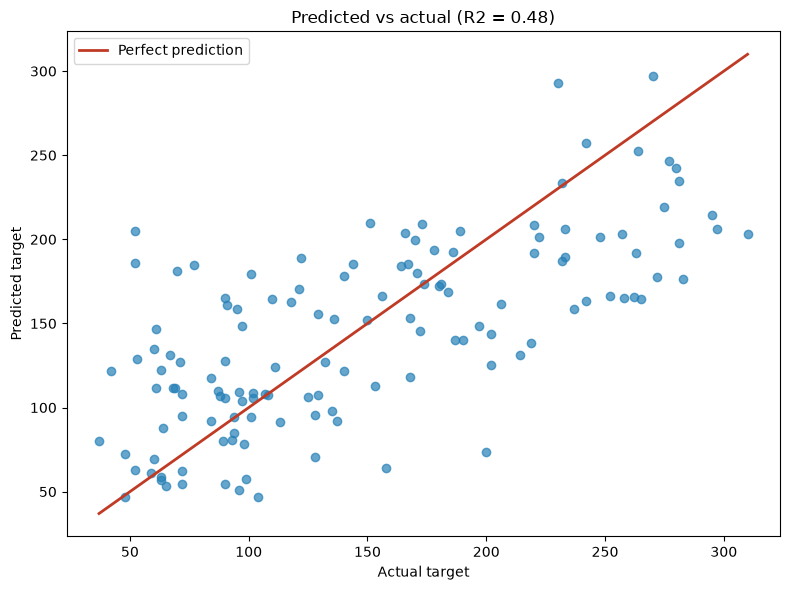

In [4]:
# Plot predicted values against the actual values.
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred, color=colors[1], alpha=0.7)
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, color=colors[3], linewidth=2,
        label="Perfect prediction")
ax.set_xlabel("Actual target")
ax.set_ylabel("Predicted target")
ax.set_title(f"Predicted vs actual (R2 = {r2:.2f})")
ax.legend()
plt.tight_layout()
plt.show()

## Residual Plot

Residuals scattered around zero with no pattern suggest the model assumptions hold reasonably well.

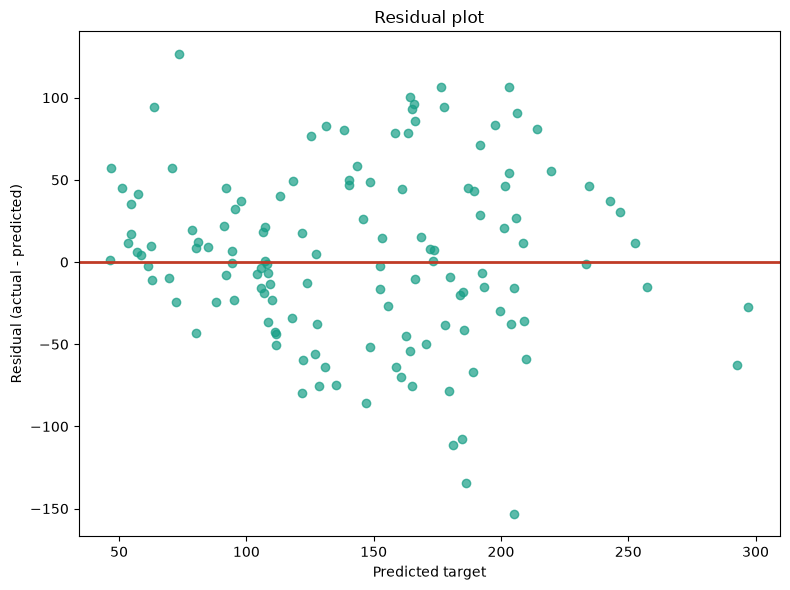

In [5]:
# Plot the residuals against the predicted values.
residuals = y_test - y_pred
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_pred, residuals, color=colors[0], alpha=0.7)
ax.axhline(0, color=colors[3], linewidth=2)
ax.set_xlabel("Predicted target")
ax.set_ylabel("Residual (actual - predicted)")
ax.set_title("Residual plot")
plt.tight_layout()
plt.show()

## Sensitivity of MSE to a Single Outlier

Corrupt one prediction with a large error and observe how MSE reacts far more strongly than MAE.

In [6]:
# Corrupt one prediction to create a single large error.
y_pred_out = y_pred.copy()
y_pred_out[0] = y_pred_out[0] + 500

# Recompute both metrics with the outlier.
mae_out = mean_absolute_error(y_test, y_pred_out)
mse_out = mean_squared_error(y_test, y_pred_out)

print(f"MAE  clean: {mae:.2f} -> outlier: {mae_out:.2f} "
      f"(x{mae_out / mae:.2f}).")
print(f"MSE  clean: {mse:.2f} -> outlier: {mse_out:.2f} "
      f"(x{mse_out / mse:.2f}).")

MAE  clean: 41.92 -> outlier: 44.47 (x1.06).
MSE  clean: 2821.75 -> outlier: 4095.96 (x1.45).


## Visualise the Effect

Plot the relative increase of each metric caused by the single outlier.

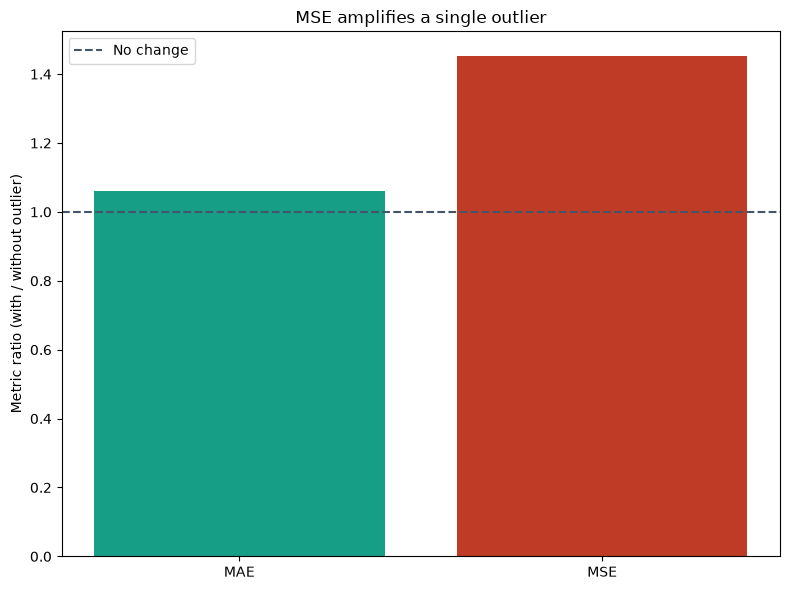

In [7]:
# Plot the relative increase caused by the outlier.
fig, ax = plt.subplots(figsize=(8, 6))
labels = ["MAE", "MSE"]
ratios = [mae_out / mae, mse_out / mse]
ax.bar(labels, ratios, color=[colors[0], colors[3]])
ax.axhline(1.0, color=colors[4], linestyle="--",
           label="No change")
ax.set_ylabel("Metric ratio (with / without outlier)")
ax.set_title("MSE amplifies a single outlier")
ax.legend()
plt.tight_layout()
plt.show()

## Summary

- **MAE**: mean absolute error, robust and in target units.
- **MSE / RMSE**: square the errors, so large mistakes dominate; RMSE restores the original units.
- **R-squared**: fraction of variance explained, scale-free and easy to compare across problems.
- **Outliers**: MSE grows far faster than MAE under a single big error, so choose the metric that matches your tolerance.